# Basic scenario creation using the `MandyocBuilder`class

The `MandyocBuilder` is a generic class to assist users in scenario creation. The built-in functions facilitate the creation of the conservative velocity field and the temperature field creation, given the boundary conditions for the lithosphere. 

## Creating the MandyocBuilder

In [1]:
# Loading useful packages

import os
import numpy as np
import matplotlib.pyplot as plt

# Importing variables and Builders from tapioca
from tapioca import DEFAULT_MATERIALS
from tapioca.inputs import MandyocBuilder, VelocityFieldBuilder, TemperatureFieldBuilder

In [2]:
# The materials are frozen dictionaries that contain the rheological parameters used in Mandyoc:
print(f'Materials: {list(DEFAULT_MATERIALS.keys())}')
print(f'Rheological parameters for "wet olivine": {DEFAULT_MATERIALS["WET_OLIVINE"]}')

Materials: ['WET_OLIVINE', 'DRY_OLIVINE', 'WET_QUARTZ', 'WET_ANORTHITE', 'LINEAR_SALT', 'AIR']
Rheological parameters for "wet olivine": {'C': 1.0, 'rho': 3378.0, 'H': 0.0, 'A': 1.393e-14, 'n': 3.0, 'Q': 429000.0, 'V': 1.45e-05, 'k': 1e-06, 'weakening_seed': -1.0, 'cohesion_min': 4000000.0, 'cohesion_max': 20000000.0, 'friction_angle_min': 4.0, 'friction_angle_max': 15.0}


### Setting the domain
The initial thing is to set the Lx, Lz, Nx, and Nz parameters. Creation of 3D scenarios are not supported yet.

In [3]:
# Defining the domain size and grid resolution
lx = 1200.0e3 # m
lz = 400.0e3  # m
dx = 1.0e3    # m
dz = 1.0e3    # m

# Defining the nodes in x and z
nx = int(lx/dx) + 1
nz = int(lz/dz) + 1

# Creating a MandyocBuilder object to generate the input files for Mandyoc, 
# the folder is created if it does not exist.
# It is convenient to keep verbose True to see the progress of the input file generation
scen = MandyocBuilder(f'scenario_example', 
                      Nx=nx, Nz=nz, 
                      Lx=lx, Lz=lz, 
                      verbose=True)

## Creating the interfaces

The interfaces creation are generally exaustive. The interfaces.txt for mandyoc required stacked interfaces, from the bottom to the top. Using the MandyocBuilder, it is possible to create interfaces from numpy arrays with Nx elements, a bunch of X,Z points, and Shapely polygons.

Notice that in Manyoc, the indexing starts in the lower left corner (x = 0, z = -Lz) up to the upper right (x = Lx, z = 0).

In [4]:
# layers thickness

t_air = 40.0e3 # m - sticky air
t_uc = 23.0e3 # m - upper crust
t_lc = 10.0e3 # m - lower crust
t_litho = 120.0e3 # m - lithosphere (lith. mantle + crust)


# Stacking the layers to get the depth of the interfaces

d_surf = -(t_air) # Surface
d_lc = -(t_uc+t_air) # Lower-upper crust interface
d_moho = -(t_lc+t_uc+t_air) # Moho
d_lab = -(t_litho+t_air) # LAB

In [5]:
# Creating a weak seed with a polygon
from shapely import Polygon

x_ws = int(lx/3) # m - x position of the weak seed
d_ws = d_moho - 13.0e3 # m - 13 km under the lithospheric mantle
t_ws = 5.0e3 # m - thickness of the weak seed
l_ws = 5.0e3 # m - length of the weak seed

ws_poly = Polygon(
                  [(x_ws-l_ws/2,d_ws+t_ws/2), # 1       1------2
                   (x_ws+l_ws/2,d_ws+t_ws/2), # 2       |      |
                   (x_ws+l_ws/2,d_ws-t_ws/2), # 3       |      |
                   (x_ws-l_ws/2,d_ws-t_ws/2)] # 4       4------3
                   )

### Rheology
Tapioca expect the rheology through a dictionary. Users could copy some classic rheologies from the `DEFAULT_MATERIALS`.

In [6]:
# Upper crust - weak
uc = DEFAULT_MATERIALS['WET_QUARTZ'].copy()
uc['H']=4.8e-10 # W/kg
uc['friction_angle_max'] = 20.0
uc['friction_angle_min'] = 5.0
uc['cohesion_min'] = 1.0e6 

# Lower crust - strong
lc = DEFAULT_MATERIALS['WET_ANORTHITE'].copy()
lc['rho'] = 2800.0
lc['C'] = 0.75
lc['friction_angle_max'] = 20.0
lc['friction_angle_min'] = 5.0
lc['cohesion_min'] = 5.0e6

# Lithospheric mantle - dry olivine
lm = DEFAULT_MATERIALS['DRY_OLIVINE'].copy()
# Asthenosphere - wet olivine
ast = DEFAULT_MATERIALS['WET_OLIVINE'].copy()

lm['k'] = ast['k'] = 1.2e-6
lm['friction_angle_max'] = ast['friction_angle_max'] = 20.0
lm['friction_angle_min'] = ast['friction_angle_min'] = 5.0
lm['cohesion_min'] = ast['cohesion_min'] = 5e6

# air - sticky air
air = DEFAULT_MATERIALS['AIR'].copy()


# weak seed - fragile mantle
ws = lm.copy()
ws['C'] = 0.1
ws['weakening_seed'] = 1.0

## Setting the interfaces
It is important to correctly set the interface's ID, according to their order in the stacking.

In [7]:
# Generally the ID 0 is the LAB
scen.create_interface(0,d_lab,interface_name='asthenosphere',**ast)

scen.create_interface(1,d_moho, interface_name='lithospheric_mantle',**lm)
scen.create_interface(2,d_lc, interface_name='lower_crust',**lc)
scen.create_interface(3,d_surf, interface_name='upper_crust',**uc)
scen.create_interface(-1,d_surf, interface_name='air',**air)

# adding the weak seed as an interface, setting the split line to the middle of the polygon
scen.add_interface_from_shapely('lithospheric_mantle', ws_poly, 'weak_seed', 'mid',**ws)

ID 0 -> asthenosphere
C:1.0; rho:3378.0; H:0.0; A:1.393e-14; n:3.0; Q:429000.0; V:1.45e-05; k:1.2e-06; weakening_seed:-1.0; cohesion_min:5000000.0; cohesion_max:20000000.0; friction_angle_min:5.0; friction_angle_max:20.0; 
The interface is a flat line/surface
ID 1 -> lithospheric_mantle
C:1.0; rho:3354.0; H:9e-12; A:2.417e-15; n:3.5; Q:540000.0; V:2.45e-05; k:1.2e-06; weakening_seed:-1.0; cohesion_min:5000000.0; cohesion_max:20000000.0; friction_angle_min:5.0; friction_angle_max:20.0; 
The interface is a flat line/surface
ID 2 -> lower_crust
C:0.75; rho:2800.0; H:7.123e-11; A:3.9810717e-16; n:3.0; Q:356000.0; V:0.0; k:1.15e-06; weakening_seed:-1.0; cohesion_min:5000000.0; cohesion_max:25000000.0; friction_angle_min:5.0; friction_angle_max:20.0; 
The interface is a flat line/surface
ID 3 -> upper_crust
C:1.0; rho:2700.0; H:4.8e-10; A:8.574e-28; n:4.0; Q:222000.0; V:0.0; k:1e-06; weakening_seed:-1.0; cohesion_min:1000000.0; cohesion_max:20000000.0; friction_angle_min:5.0; friction_angle_

After the interfaces creation, the user must to create parameters fields, considering the materials

In [8]:
scen.create_materials_fields()

Sorting interfaces by ID:
air-asthenosphere-bot_weak_seed-top_weak_seed-lithospheric_mantle-lower_crust-upper_crust
Field created: density [kg/m3]
Field created: scale_factor [dimensionless]
Field created: radiogenic_heat [W/kg]
Field created: pre-exponential_scale_factor [Pa^(-n)/s]
Field created: power_law_exponent [dimensionless]
Field created: activation_energy [J/mol]
Field created: activation_volume [m3/mol]
Field created: thermal_diffusivity [m2/s]
Field created: weak_seed_strain [dimensionless]
Field created: cohesion_min [Pa]
Field created: cohesion_max [Pa]
Field created: friction_angle_min [degrees]
Field created: friction_angle_max [degrees]


All fields interfaces are stored in a DataTree within the builder. The DataTree has the nodes `fields`, with `z,x` dimensions, and `interfaces` with x dimension. 

In [9]:
display(scen.DTree)

<xarray.DataTree>
Group: /
├── Group: /fields
│       Dimensions:             (z: 401, x: 1201)
│       Coordinates:
│         * z                   (z) float64 3kB -4e+05 -3.99e+05 ... -1e+03 0.0
│         * x                   (x) float64 10kB 0.0 1e+03 2e+03 ... 1.199e+06 1.2e+06
│       Data variables: (12/13)
│           rho                 (z, x) float64 4MB 3.378e+03 3.378e+03 ... 1.0 1.0
│           C                   (z, x) float64 4MB 1.0 1.0 1.0 1.0 ... 0.1 0.1 0.1 0.1
│           H                   (z, x) float64 4MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
│           A                   (z, x) float64 4MB 1.393e-14 1.393e-14 ... 1e-18 1e-18
│           n                   (z, x) float64 4MB 3.0 3.0 3.0 3.0 ... 1.0 1.0 1.0 1.0
│           Q                   (z, x) float64 4MB 4.29e+05 4.29e+05 ... 0.0 0.0
│           ...                  ...
│           k                   (z, x) float64 4MB 1.2e-06 1.2e-06 ... 1e-05 1e-05
│           weakening_seed      (z, x) float64 4MB -1.0 -1.0 -1.0 ... -1.0 -1.0 -1.0
│           cohesion_min        (z, x) float64 4MB 5e+06 5e+06 5e+06 ... 1e+05 1e+05
│           cohesion_max        (z, x) float64 4MB 2e+07 2e+07 2e+07 ... 1e+06 1e+06
│           friction_angle_min  (z, x) float64 4MB 5.0 5.0 5.0 5.0 ... 2.0 2.0 2.0 2.0
│           friction_angle_max  (z, x) float64 4MB 20.0 20.0 20.0 20.0 ... 5.0 5.0 5.0
│       Attributes:
│           description:  This group contains the fields of the model, each variable ...
└── Group: /interfaces
        Dimensions:              (x: 1201)
        Coordinates:
          * x                    (x) float64 10kB 0.0 1e+03 2e+03 ... 1.199e+06 1.2e+06
        Data variables:
            air                  (x) float64 10kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
            asthenosphere        (x) float64 10kB -1.6e+05 -1.6e+05 ... -1.6e+05
            bot_weak_seed        (x) float64 10kB -8.6e+04 -8.6e+04 ... -8.6e+04
            top_weak_seed        (x) float64 10kB -8.6e+04 -8.6e+04 ... -8.6e+04
            lithospheric_mantle  (x) float64 10kB -7.3e+04 -7.3e+04 ... -7.3e+04
            lower_crust          (x) float64 10kB -6.3e+04 -6.3e+04 ... -6.3e+04
            upper_crust          (x) float64 10kB -4e+04 -4e+04 -4e+04 ... -4e+04 -4e+04
        Attributes:
            description:  This group contains the interfaces of the model, each inter...

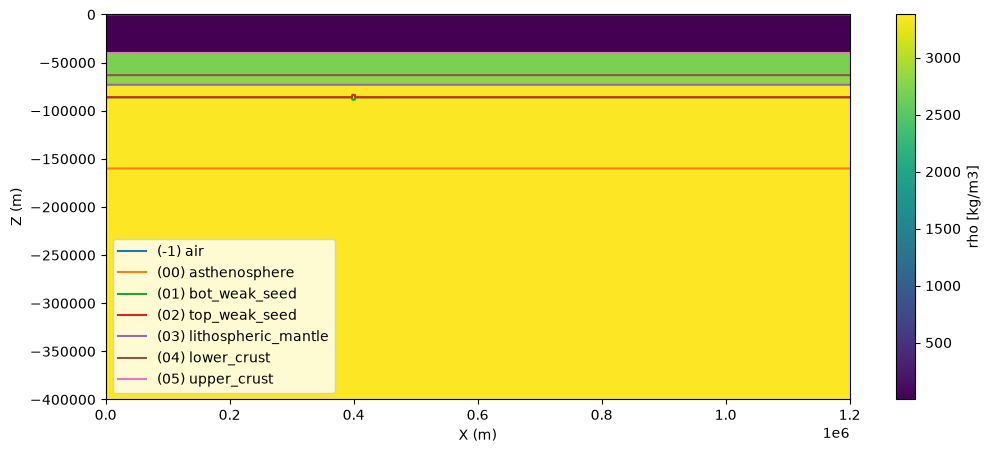

In [10]:
# Quick check in the fields and interfaces 
plt.figure(figsize=(12,5))

scen.DTree.fields.rho.plot.pcolormesh(x='x')
for ds in scen.DTree.interfaces.values():
    ds.plot(x='x',label=f'({ds.attrs["id"]:02d}) {ds.name}')


plt.xlabel('X (m)')
plt.ylabel('Z (m)')
plt.xlim(0,scen.Lx)
plt.ylim(scen.Lz,0)
plt.legend(loc='lower left')

## Creating the velocity field

The velocity field creation is facilited by the `VelocityFieldBuilder` class, that get the `MandyocBuilder` as input. The class manipulates only the boundaries (left, right, top, bot).

Here, we going to create a rift regime applying a constant velocity in the crust, in both sides, and a linear profile in the mantle. The field must be conservative. The builder accepts velocities in cm/y and m/s

In [11]:
v_rift = 0.25 # cm/y
# Creating the velocity builder object
velocbuild = VelocityFieldBuilder(scen, units='cm/y')


# offsets to the air and the lithosphere
air_offset = 10e3 #m
ast_offset = 20e3 #m

# constant velocity in the lithosphere
velocbuild.set_region('right',[(d_lab-ast_offset),(d_surf+air_offset)],vx=v_rift, vz=0) # constant velocity in the right

# getting the integral of the field to calculate the influx and outflux on the boundaries
int_out = velocbuild.integrate_normal_components()*velocbuild.unifac_int # integral of outflux cm²/y 
in_range = ((d_lab-ast_offset)-(-lz+t_air))*100 # cm
v_ast = (-2*int_out / in_range)-v_rift  # asthenospheric normal velocity in z=Lz

# Applying the velocity profile in the asthenosphere
velocbuild.linear_velocity('right','vx',range=[scen.Lz,(d_lab-ast_offset)],
                           clims=[scen.Lz,(d_lab-ast_offset)],
                           vlims=[v_ast,v_rift])

# Doing the same thing for the left boundary, but with opposite velocities
velocbuild.set_region('left',[(d_lab-ast_offset),(d_surf+air_offset)],vx=-v_rift, vz=0) # constant velocity in the left
velocbuild.linear_velocity('left','vx',range=[scen.Lz,(d_lab-ast_offset)],
                           clims=[scen.Lz,(d_lab-ast_offset)],
                           vlims=[-v_ast,-v_rift])

# Checking the velocity field conservation:
print(f"Integral of normal components: {velocbuild.integrate_normal_components():.8f} m²/s")

Velocity is given in cm/y. The field will be automatically converted to m/s
The velocity builder was created.
(set) velocity in the right: from [-180000.0,-30000.0], vx=2.500e-01, vz=0.000e+00 cm/y
Int V = 1.196e-05 m²/s
linear velocity in the right boundary: vx = 4.179e-06 * COORD + 1.002e+00
(set) velocity in the left: from [-180000.0,-30000.0], vx=-2.500e-01, vz=0.000e+00 cm/y
linear velocity in the left boundary: vx = -4.179e-06 * COORD + -1.002e+00
Int V = -5.396e-06 m²/s
Integral of normal components: -0.00000540 m²/s


Int V = -5.396e-06 m²/s
(add) velocity in the bot: from [0.0,1200000.0], vx=0.000e+00, vz=-1.419e-02 cm/y
Int V = -8.470e-22 m²/s
(add) velocity in the bot: from [0.0,1200000.0], vx=0.000e+00, vz=-2.228e-18 cm/y
Int V = 0.000e+00 m²/s
(add) velocity in the bot: from [0.0,1200000.0], vx=0.000e+00, vz=0.000e+00 cm/y
Int V = 0.000e+00 m²/s
(add) velocity in the bot: from [0.0,1200000.0], vx=0.000e+00, vz=0.000e+00 cm/y
Int V = 0.000e+00 m²/s
(add) velocity in the bot: from [0.0,1200000.0], vx=0.000e+00, vz=0.000e+00 cm/y
Int V = 0.000e+00 m²/s
(add) velocity in the bot: from [0.0,1200000.0], vx=0.000e+00, vz=0.000e+00 cm/y
Int V = 0.000e+00 m²/s
(add) velocity in the bot: from [0.0,1200000.0], vx=0.000e+00, vz=0.000e+00 cm/y
Int V = 0.000e+00 m²/s
(add) velocity in the bot: from [0.0,1200000.0], vx=0.000e+00, vz=0.000e+00 cm/y
Int V = 0.000e+00 m²/s
(add) velocity in the bot: from [0.0,1200000.0], vx=0.000e+00, vz=0.000e+00 cm/y
Int V = 0.000e+00 m²/s
(add) velocity in the bot: from [0.0,

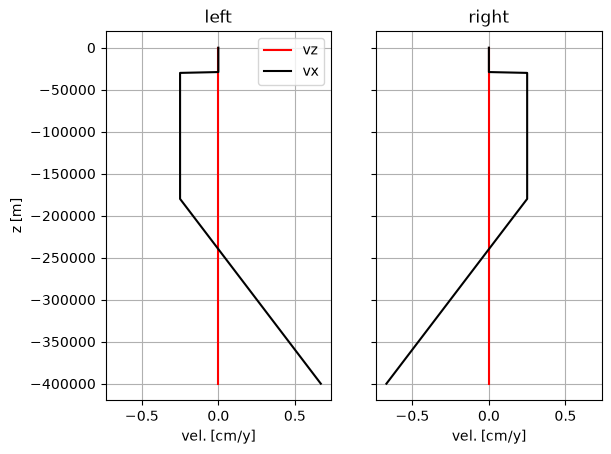

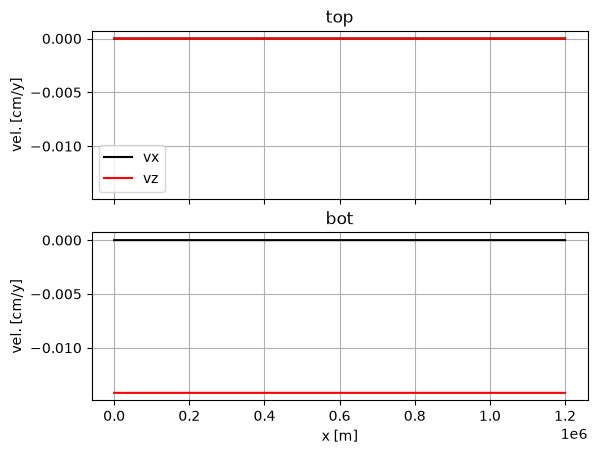

In [12]:
# conservating the velocity field in the bottom boundary
# a loop to ensure that the flux is being conservated
for i in range(10):
    velocbuild.conservate_veloc('bot',1.0)

# viewing the velocity in the boundaries
lr, bt = velocbuild.view_veloc()
lr.savefig(os.path.join(scen.path,'v_lr.png'),bbox_inches='tight')
bt.savefig(os.path.join(scen.path,'v_bt.png'),bbox_inches='tight')

In [13]:
# creating the velocity field in the MandyocBuilder object
scen.create_velocity_field(velocbuild)

Velocity field was created in the scenario builder.


## Creating the temperature field
The temperature is created using the `TemperatureFieldBuilder` class, that also recieves the `MandyocBuilder` as input.

Currently, the temperature field depends of the LAB and the surface interfaces.

In [14]:
# Creating the temperature field builder, setting the interfaces, 
# the heat capacity, the gravity and the thermal diffusivity
tempbuild = TemperatureFieldBuilder(scen,surface_interface=5,LAB_interface=0,
                                    c_cap=1250,g=-10,alpha = 0.0000328)

# initializing the temperature field with a linear profile between the surface and the LAB
# below the LAB, the temperature is given by the adibatic heat profile
tempbuild.apply_linear_temperature(t_pot=1350)

The `TemperatureFieldBuilder` has three temperature solvers: `solve_heat_2D`, `solve_heat_1D`, `solve_heat_column`. The documentation for each method can be consulted in the docstrings. 

For 2D fields, the builder solves the heat equation fot a steady state field, using an analytical solution through scipy: 

$\frac{d}{dx} (k dT/dx) + \frac{d}{dz} (k dT/dz) + H = 0$

In which k is the thermal conductivity (obtained from the density and the thermal diffusivity), and H is the radiogenic heat. 

The assemble of the sparse matrices are accelerated using the numba JIT.  

Solving the 2D heat equation
Diagonals prepared


/home/jobueno/miniconda3/envs/tapioca/lib/python3.14/site-packages/IPython/core/events.py:100: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


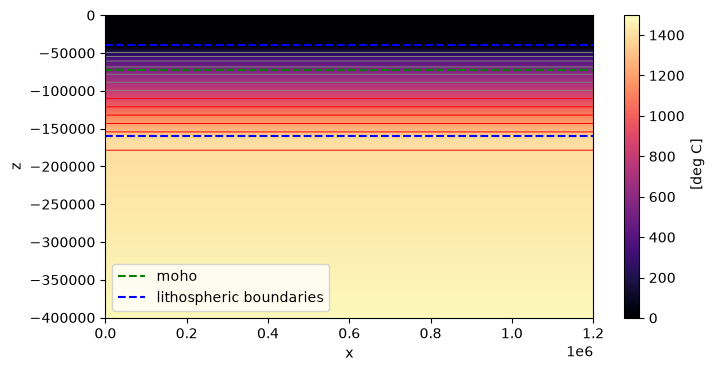

In [15]:
# solving the heat equation in 2D to get the temperature field
tempbuild.solve_heat_2D()

# Visualizing the temperature field
plt.figure(figsize=(20,10,'cm'))
tempbuild.temperature.plot(y='z',vmin=0,vmax=1500,cmap='magma')
tempbuild.temperature.plot.contour(y='z',colors='gray',levels=np.arange(200,801,100),lw=0.7)
tempbuild.temperature.plot.contour(y='z',colors='red',levels=np.arange(900,1600,100),lw=0.7)

plt.axhline(d_surf,color='blue',ls='--',lw=1.5)
plt.axhline(d_moho,color='green',ls='--',lw=1.5,label='moho')
plt.axhline(d_lab,color='blue',ls='--',lw=1.5,label='lithospheric boundaries')
plt.legend()

If the user want to customize the field, applying thermal anomalies or any filter, is it possible to manipulate it just modifying the `temperature` DataArray within the builder. 

In [16]:
# Passing the temperature field to the MandyocBuilder object
scen.create_temperature_field(tempbuild)

Temperature field was created in the scenario builder.


## Visualizing the Yield Stress Envelope

The builder can calculate the lithospheric pressure-based on the density, thermal expansion, and temperature-to create the YSE of the initial setup:

Using thermal expansion coefficient used in the `TemperatureFieldBuilder`: alpha=3.28e-05
Lithostatic pressure was calculated.
Plastic rheology: Drucker-Prager Criterion
Viscous rheology: dislocation creep
Yield Strength Envelopte was calculated.


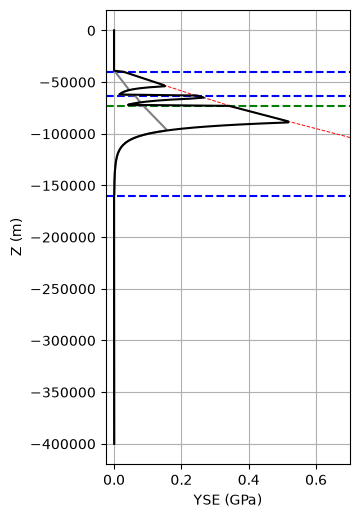

In [17]:
# Calculating the YSE given a strain rate of 1e-15 s^-1, 
# which is a typical value for lithospheric deformation
scen.calculate_YSE(sr=1e-15)

# Visualizing the YSE field, in GPa

plt.figure(figsize=(8,15,'cm'))
plt.axhline(d_surf,color='blue',ls='--',lw=1.5)
plt.axhline(d_lc,color='blue',ls='--',lw=1.5)
plt.axhline(d_moho,color='green',ls='--',lw=1.5,label='moho')
plt.axhline(d_lab,color='blue',ls='--',lw=1.5,label='lithospheric boundaries')

# Geting the YSE in the position 101
plt.plot(scen.DTree.fields.plastic_YSE[:,101]/1e9, scen.DTree.fields.z, color='red',ls='--',lw=0.7)
plt.plot(scen.DTree.fields.YSE_soft[:,101]/1e9,scen.DTree.fields.z,color='gray')
plt.plot(scen.DTree.fields.YSE[:,101]/1e9,scen.DTree.fields.z,color='black')

plt.xlabel('YSE (GPa)')
plt.ylabel('Z (m)')
plt.xlim(-0.025,0.7)
plt.grid()

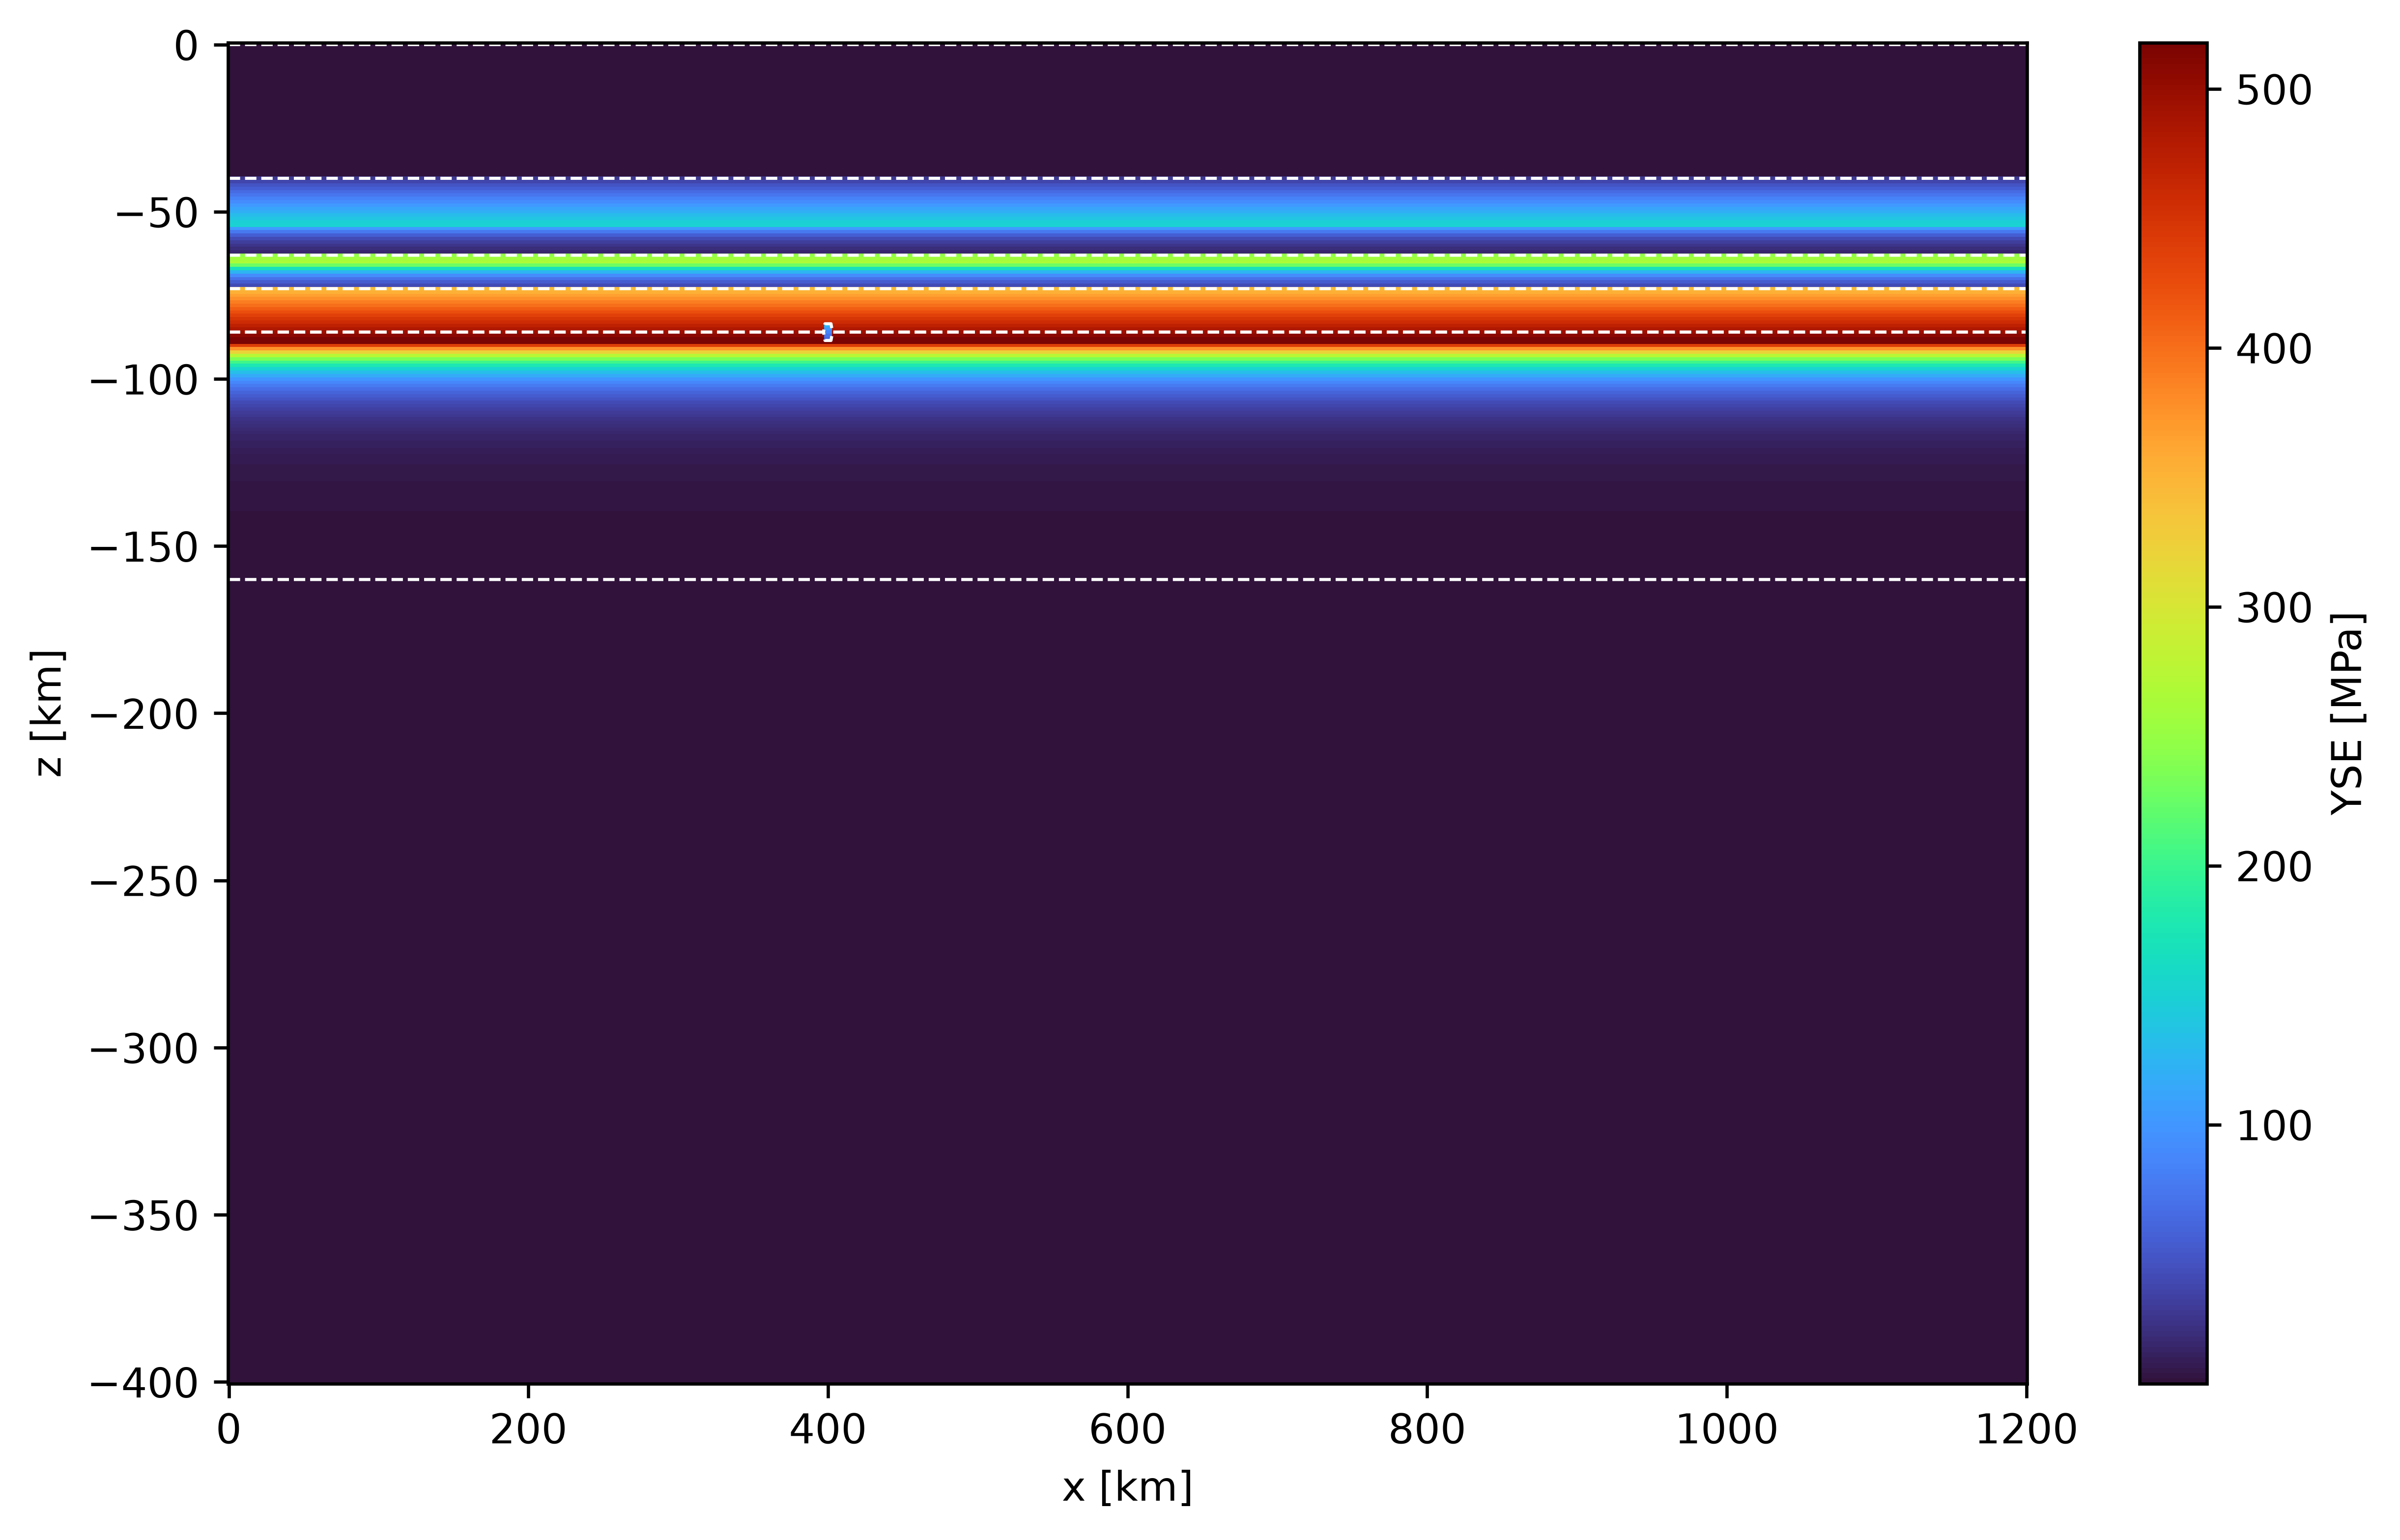

In [18]:
# Visualizing the YSE field in 2D, which is useful to see the envelope in complexes scenarios

yse_field = scen.DTree.fields.YSE/1e6

fig, ax = plt.subplots(figsize=(25, 15,'cm'),dpi=600)
yseplot = ax.pcolormesh(scen.DTree.fields.x/1e3,scen.DTree.fields.z/1e3,yse_field, cmap='turbo',rasterized=True)

for ds in scen.DTree.interfaces.values():
    ax.plot(ds.x/1e3, ds.values/1e3,label=f'({ds.name}',color='white',ls='--',lw=0.75)

fig.colorbar(yseplot,label='YSE [MPa]')

ax.set_ylabel('z [km]')
ax.set_xlabel('x [km]')
# ax.set_ylim(-200,-20)

fig.savefig(os.path.join(scen.path,f'YSE_field.png'),dpi=300,bbox_inches='tight')

## Exporting the interfaces and the fields
We can export the interfaces and generate a csv with the used rheologies. The fields can be exported following the example:

In [19]:
scen.export_interfaces(export='csv')
scen.export_field('velocity')
scen.export_field('temperature')

Exporting dataset to interfaces.txt
Interfaces: asthenosphere -> bot_weak_seed -> top_weak_seed -> lithospheric_mantle -> lower_crust -> upper_crust -> air
Exporting interfaces to CSV file
Exporting velocity field (963202)
Exporting temperature field (481601)


## The `param.txt` file
The parameters for the simulation could be set through plain texts or dictionaries. For parameters that were set before (such as gravity, etc), the builder does not allow the overwritting.

In [20]:
# Creating the parameters dictionary to set the parameters in the MandyocBuilder object
params_dict = {   
    'particles_per_element':100,
    'particles_per_element_x':10,
    'particles_per_element_z':10,
    'particles_perturb_factor':0.7,

    ## Inputs
    'interfaces_from_ascii':True, 
    'temperature_from_ascii':True, 
    'velocity_from_ascii':True, 
    'water_interface':-1,

    ## Magmatism
    'magmatism':'off', 
    'magmatism_extraction':'off', 
    'magmatic_layer':-1, 

    ## Numerical
    'solver':'direct', 
    'denok':1.0e-15,
    'Xi_min':5.0e-6,
    'non_linear_method':'on', 

    ## Time    
    'step_max':5000,
    'step_print':20,
    'time_max':70.0e6,
    'dt_max':20.0e3,
    'sub_division_time_step':0.5,
    'initial_print_step':0,

    ## Rheology
    'initial_dynamic_range':True, 
    'viscosity_reference':1.0e21,
    'viscosity_min':1.0e18,
    'viscosity_max':1.0e25,
    'viscosity_per_element':'constant', 
    'viscosity_mean_method':'arithmetic', 
    'viscosity_dependence':'pressure', 

    'random_initial_strain':0.5,
    'rheology_model':9,
    'weakening_min':0.05,
    'weakening_max':1.05,

    # Temperature and other parameters 
    'adiabatic_component':'on', 
    'shear_heating':'off',
    'radiogenic_component':'on', 
    'high_kappa_in_asthenosphere':False, 

    # Physical parameters
    'density_mantle':3300.0,
    'gravity_acceleration':10.0,
    'thermal_expansion_coefficient':3.28e-5,
    'heat_capacity':1250.0,

    # Surface processes
    'sp_surface_tracking':True, 
    'surface_particles_per_element':50,
    'sp_surface_processes':False, 

    'free_surface_stab':True, 
    'theta_FSSA':0.5,
    
    'sp_mode':'none',
    'sticky_blanket_air':True, 
    'a2l':True, 

    
    # Boundary conditions
    
    'top_normal_velocity':'fixed', 
    'bot_normal_velocity':'fixed', 
    'left_normal_velocity':'fixed', 
    'right_normal_velocity':'fixed',  
    
    'top_tangential_velocity':'fixed', 
    'bot_tangential_velocity':'free', 
    'left_tangential_velocity':'free', 
    'right_tangential_velocity':'free', 
    
    'top_temperature':'fixed', 
    'bot_temperature':'fixed', 
    'left_temperature':'free', 
    'right_temperature':'free', 

    'variable_bcv':False, 
    'bcv_extern':False,   
    'multi_velocity':False,  

    # Outputs
    'export_thermal_diffusivity':True,
    'print_step_files':True, 
    'export_lithology':True
}

# setting and exporting to param.txt
scen.set_params(**params_dict).export_params()

interfaces_from_ascii was already set in the builder.
temperature_from_ascii was already set in the builder.
velocity_from_ascii was already set in the builder.
gravity_acceleration was already set in the builder.
thermal_expansion_coefficient was already set in the builder.
heat_capacity was already set in the builder.


Additionally, the whole input can be exported into a single NetCDF file, using the function `export_compressed_datatree`.

In [21]:
from tapioca import export_compressed_datatree

path_file = os.path.join(scen.path,"MODEL_INPUTS.nc")
export_compressed_datatree(scen.DTree, path_file)

Notice that the `param.txt` can be set this way:

``` python
params = f"""
# Simulation options
multigrid                           = 1             # ok -> soon to be on the command line only
solver                              = direct        # default is direct [direct/iterative]
denok                               = 5.0e-15       # default is 1.0E-4
particles_per_element               = 100           # default is 81
particles_perturb_factor            = 0.7           # default is 0.5 [values are between 0 and 1]
rtol                                = 1.0e-7        # the absolute size of the residual norm (relevant only for iterative methods), default is 1.0E-5
RK4                                 = Euler         # default is Euler [Euler/Runge-Kutta]
Xi_min                              = 5.0e-6        # default is 1.0E-14
random_initial_strain               = 0.5           # default is 0.0
pressure_const                      = -1.0          # default is -1.0 (not used) - useful only in horizontal 2D models
initial_dynamic_range               = True          # default is False [True/False]
periodic_boundary                   = False         # default is False [True/False]
high_kappa_in_asthenosphere         = False         # default is False [True/False]
K_fluvial                           = 2.0e-7        # default is 2.0E-7
m_fluvial                           = 1.0           # default is 1.0
sea_level                           = 0.0           # default is 0.0
basal_heat                          = 0.0           # default is -1.0

# Surface processes
sp_surface_tracking                 = True          # default is False [True/False]
sp_surface_processes                = True          # default is False [True/False]
sp_d_c                              = 1.0           # default is 0.0
plot_sediment                       = False         # default is False [True/False]
a2l                                 = True          # default is True [True/False]
sp_mode                             = theunissen_sedimentation #[none/sedimentation_rate_limited]
variable_base_level                 = True          # default is False [True/False]
surface_particles_per_element       = 50 
continental_slope                   = 2.0           #default is 2.0
strain_sed                          = 0.25           #default is 0.6

free_surface_stab                   = True          # default is True [True/False]
theta_FSSA                          = 0.5           # default is 0.5 (only relevant when free_surface_stab = True)

# Time constrains
step_max                            = 25000         # Maximum time-step of the simulation
time_max                            = {int(t_max)}.0e6        # Maximum time of the simulation [years]
dt_max                              = 20.0e3        # Maximum time between steps of the simulation [years]
step_print                          = 20            # Make file every <step_print>
sub_division_time_step              = 0.25          # default is 1.0
initial_print_step                  = 0             # default is 0
initial_print_max_time              = 1.0e6         # default is 1.0E6 [years]

# Viscosity
viscosity_reference                 = 1.0e21        # Reference viscosity [Pa.s]
viscosity_max                       = 1.0e25        # Maximum viscosity [Pa.s]
viscosity_min                       = 1.0e18        # Minimum viscosity [Pa.s]
viscosity_per_element               = constant      # default is variable [constant/variable]
viscosity_mean_method               = arithmetic    # default is harmonic [harmonic/arithmetic]
viscosity_dependence                = pressure      # default is depth [pressure/depth]

# External ASCII inputs/outputs
interfaces_from_ascii               = True          # default is False [True/False]
variable_bcv                        = False         # default is False [True/False]
temperature_from_ascii              = True          # default is False [True/False]
velocity_from_ascii                 = True          # default is False [True/False]
binary_output                       = False         # default is False [True/False]
sticky_blanket_air                  = True          # default is False [True/False]

export_thermal_diffusivity = True
export_lithology                    = True
print_step_files                    = True          # default is True [True/False]
checkered                           = False          # Print mora than one element in the print_step_files (default is False [True/False])

geoq                                = on            # ok
geoq_fac                            = 100.0         # ok

# Physical parameters
temperature_difference              = 1500.         # ok
thermal_expansion_coefficient       = 3.28e-5       # ok
thermal_diffusivity_coefficient     = 1.0e-6        # ok
gravity_acceleration                = 10.0          # ok
density_mantle                      = 3300.         # ok
external_heat                       = 0.0e-12       # ok
heat_capacity                       = 1250.         # ok

non_linear_method                   = on            # ok
adiabatic_component                 = on            # ok
radiogenic_component                = on            # ok

# Velocity boundary conditions
top_normal_velocity                 = fixed         # ok
top_tangential_velocity             = fixed          # ok
bot_normal_velocity                 = fixed         # ok
bot_tangential_velocity             = free          # ok
left_normal_velocity                = fixed         # ok
left_tangential_velocity            = free         # ok
right_normal_velocity               = fixed         # ok
right_tangential_velocity           = free         # ok

surface_velocity                    = 0.0e-2        # ok
multi_velocity                      = False         # default is False [True/False]

# Temperature boundary conditions
top_temperature                     = fixed         # ok
bot_temperature                     = fixed         # ok
left_temperature                    = free         # ok - set free to variable diffusivity
right_temperature                   = free         # ok

rheology_model                      = 9            # ok
T_initial                           = 3             # ok
"""

scen.set_params(params_str=params).export_params()
```